In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

# Establish structural reproducibility
np.random.seed(101)
n_buildings = 12

# Generate facility profiles
building_types = ['Science Lab', 'General Classroom', 'Administrative Hub', 'Athletic Complex', 'Residence Hall', 'Library']
data = {
    'Building_ID': [f'BLDG-{100+i}' for i in range(n_buildings)],
    'Facility_Type': np.random.choice(building_types, n_buildings),
    'Square_Footage': np.random.randint(15000, 120000, n_buildings),
    'Insulation_Efficiency_Score': np.random.uniform(1.0, 5.0, n_buildings).round(2), # 1=Poor, 5=Excellent
    'HVAC_System_Age_Years': np.random.randint(1, 18, n_buildings),
    'Baseline_Annual_Utility_Cost': np.random.randint(45000, 280000, n_buildings)
}

df_facilities = pd.DataFrame(data)
print("✅ Phase 1 Complete: Institutional facility matrix generated successfully!")
df_facilities.head(4)


✅ Phase 1 Complete: Institutional facility matrix generated successfully!


,Building_ID,Facility_Type,Square_Footage,Insulation_Efficiency_Score,HVAC_System_Age_Years,Baseline_Annual_Utility_Cost
0,BLDG-100,Athletic Complex,34566,3.92,8,238523
1,BLDG-101,General Classroom,101493,2.10,7,251287
2,BLDG-102,Library,47817,3.74,15,214825
3,BLDG-103,Athletic Complex,78315,3.07,10,118693


In [2]:
# Calculate energy intensity per square foot adjusted by system age and insulation gaps
df_facilities['Energy_Waste_Factor'] = (
    (df_facilities['HVAC_System_Age_Years'] * 0.6) /
    df_facilities['Insulation_Efficiency_Score']
)

# Normalize the factor into a clean 0-100 Structural Risk Score
max_waste = df_facilities['Energy_Waste_Factor'].max()
df_facilities['Structural_Risk_Score'] = ((df_facilities['Energy_Waste_Factor'] / max_waste) * 100).round(1)

# Estimate immediate emergency repair liability costs per building
df_facilities['Emergency_Failure_Liability'] = (df_facilities['Square_Footage'] * 1.75 * (df_facilities['HVAC_System_Age_Years'] / 2)).round(2)

print("✅ Phase 2 Complete: Structural Risk and Liability features successfully engineered.")
df_facilities[['Building_ID', 'Structural_Risk_Score', 'Emergency_Failure_Liability']].head(4)


✅ Phase 2 Complete: Structural Risk and Liability features successfully engineered.


,Building_ID,Structural_Risk_Score,Emergency_Failure_Liability
0,BLDG-100,22.3,241962.00
1,BLDG-101,36.5,621644.62
2,BLDG-102,43.9,627598.12
3,BLDG-103,35.6,685256.25


In [3]:
# Historical utility inflation timeline data (Years 1 to 7)
years = np.array([1, 2, 3, 4, 5, 6, 7]).reshape(-1, 1)
inflation_multiplier = np.array([1.0, 1.04, 1.11, 1.15, 1.24, 1.38, 1.55]) # Non-linear exponential spike

# Transform features to 2nd-degree polynomial inputs to capture the curved trend
poly = PolynomialFeatures(degree=2)
years_poly = poly.fit_transform(years)

# Train the curved predictive regression model
poly_model = LinearRegression()
poly_model.fit(years_poly, inflation_multiplier)

# Forecast inflation multiplier for Year 8 (Next Fiscal Cycle)
year_8_poly = poly.transform(np.array([[8]]))
predicted_multiplier_year8 = poly_model.predict(year_8_poly)[0]

# Vectorize calculation: Apply the non-linear forecast across every facility's budget column
df_facilities['Projected_Year8_Utility_Cost'] = (df_facilities['Baseline_Annual_Utility_Cost'] * (predicted_multiplier_year8 + (df_facilities['Structural_Risk_Score'] / 200))).round(2)

print(f"✅ Phase 3 Complete: Polynomial forecasting engine trained.")
print(f"Predicted System-Wide Utility Inflation Multiplier for Year 8: {predicted_multiplier_year8:.2f}x\n")
df_facilities[['Building_ID', 'Baseline_Annual_Utility_Cost', 'Projected_Year8_Utility_Cost']].head(4)


✅ Phase 3 Complete: Polynomial forecasting engine trained.
Predicted System-Wide Utility Inflation Multiplier for Year 8: 1.72x



,Building_ID,Baseline_Annual_Utility_Cost,Projected_Year8_Utility_Cost
0,BLDG-100,238523,436514.13
1,BLDG-101,251287,477714.54
2,BLDG-102,214825,416346.19
3,BLDG-103,118693,225109.75


In [4]:
# Define operational upgrading costs per building
df_facilities['Upgrade_Cost'] = (df_facilities['Square_Footage'] * 2.25).round(2)

# Define Capital Budget Constraint
CAPEX_BUDGET_LIMIT = 250000

# Calculate Financial Efficiency Ratio: Capital saved / Money spent upgrading
df_facilities['CapEx_Efficiency_Ratio'] = (df_facilities['Emergency_Failure_Liability'] / df_facilities['Upgrade_Cost']).round(2)

# Sort facilities by highest efficiency to greedily allocate capital resources safely
optimized_allocation = df_facilities.sort_values(by='CapEx_Efficiency_Ratio', ascending=False).copy()

optimized_allocation['Cumulative_Cost'] = optimized_allocation['Upgrade_Cost'].cumsum()
optimized_allocation['Approved_Funding'] = optimized_allocation['Cumulative_Cost'].apply(lambda x: 'APPROVED' if x <= CAPEX_BUDGET_LIMIT else 'DENIED_BUDGET_LIMIT')

print(" Phase 4 Complete: Capital resource optimization matrix executed.")
print(f"Total Budgets Analyzed: {optimized_allocation['Approved_Funding'].value_counts().to_dict()}")
optimized_allocation[['Building_ID', 'Upgrade_Cost', 'CapEx_Efficiency_Ratio', 'Approved_Funding']]


✅ Phase 4 Complete: Capital resource optimization matrix executed.
Total Budgets Analyzed: {'DENIED_BUDGET_LIMIT': 11, 'APPROVED': 1}


,Building_ID,Upgrade_Cost,CapEx_Efficiency_Ratio,Approved_Funding
6,BLDG-106,154392.75,6.22,APPROVED
2,BLDG-102,107588.25,5.83,DENIED_BUDGET_LIMIT
7,BLDG-107,259319.25,5.06,DENIED_BUDGET_LIMIT
10,BLDG-110,55737.00,5.06,DENIED_BUDGET_LIMIT
11,BLDG-111,97848.00,4.67,DENIED_BUDGET_LIMIT
9,BLDG-109,75354.75,4.28,DENIED_BUDGET_LIMIT
3,BLDG-103,176208.75,3.89,DENIED_BUDGET_LIMIT
0,BLDG-100,77773.50,3.11,DENIED_BUDGET_LIMIT
4,BLDG-104,210255.75,3.11,DENIED_BUDGET_LIMIT
5,BLDG-105,239944.50,3.11,DENIED_BUDGET_LIMIT


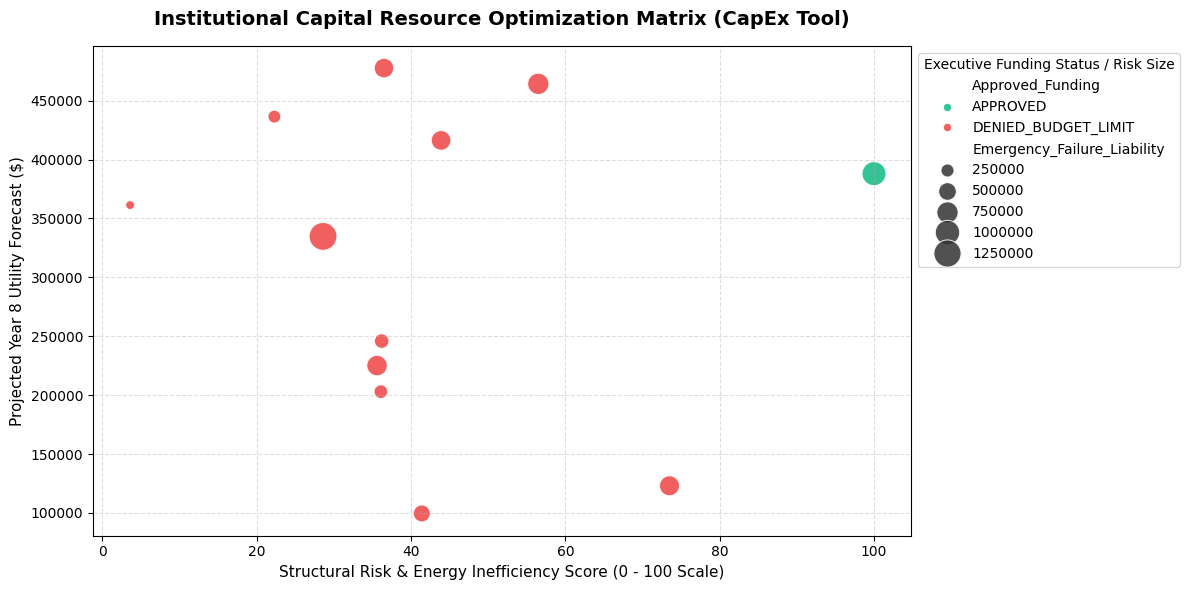

In [5]:
plt.figure(figsize=(12, 6))

# Plot facilities color-coded by approval status, sized by financial emergency liability
sns.scatterplot(
    x='Structural_Risk_Score',
    y='Projected_Year8_Utility_Cost',
    hue='Approved_Funding',
    size='Emergency_Failure_Liability',
    sizes=(40, 400),
    palette={'APPROVED': '#10B981', 'DENIED_BUDGET_LIMIT': '#EF4444'},
    data=optimized_allocation,
    alpha=0.85
)

plt.title('Institutional Capital Resource Optimization Matrix (CapEx Tool)', fontsize=14, weight='bold', pad=15)
plt.xlabel('Structural Risk & Energy Inefficiency Score (0 - 100 Scale)', fontsize=11)
plt.ylabel('Projected Year 8 Utility Forecast ($)', fontsize=11)
plt.legend(title='Executive Funding Status / Risk Size', loc='upper left', bbox_to_anchor=(1, 1))
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
